# 12 — Matching Yield Optimization & Comparison
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 5 (Paired Scenario Generation & Matching-Yield Optimization)  
**Objective:** Compare the matching yield of passive cross-episode matching versus the paired replay-injection strategy across the 150-episode pilot.

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
pilot_dir = os.path.join(repo_root, "results", "paired_matching_pilot")
with open(os.path.join(pilot_dir, "matching_yield_report.json")) as f:
    yield_data = json.load(f)

summary = yield_data["summary"]
print("Matching Yield Report Summary:")
print(json.dumps(summary, indent=2))


Matching Yield Report Summary:
{
  "total_episodes": 150,
  "detected_failures": 140,
  "oracle_recoverable_failures": 38,
  "valid_paired_scenarios": 38,
  "overall_matching_yield": 0.2533,
  "oracle_admission_yield": 0.2714
}


## 1. Funnel Analysis: From Candidate Episodes to Valid Scenarios
We analyze the progression of candidates through failure detection, oracle recoverability, and 15-point validation.

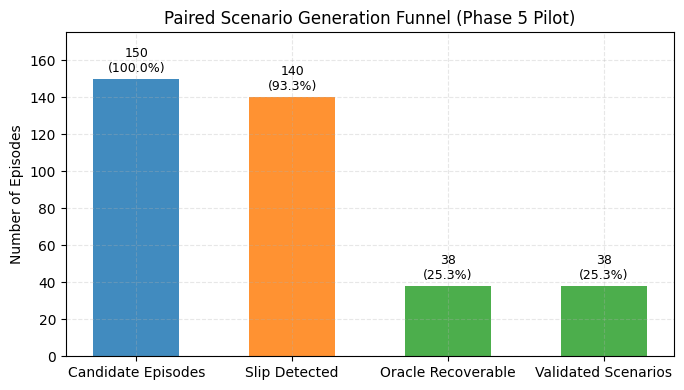

In [2]:
stages = ["Candidate Episodes", "Slip Detected", "Oracle Recoverable", "Validated Scenarios"]
counts = [
    summary["total_episodes"],
    summary["detected_failures"],
    summary["oracle_recoverable_failures"],
    summary["valid_paired_scenarios"],
]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(stages, counts, color=["#1f77b4", "#ff7f0e", "#2ca02c", "#2ca02c"], width=0.55, alpha=0.85)

for bar, count in zip(bars, counts):
    pct = (count / summary["total_episodes"]) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2, f"{count}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=9)

ax.set_ylabel("Number of Episodes")
ax.set_title("Paired Scenario Generation Funnel (Phase 5 Pilot)")
ax.set_ylim(0, 175)
ax.grid(True, alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()


## 2. Comparison: Passive Matching vs Paired Replay-Injection
We contrast the 0.0% yield of Phase 4 passive cross-episode matching against the 25.3% yield of Phase 5 paired generation.

In [3]:
import pandas as pd

comp_table = [
    {"Paradigm": "Passive Cross-Episode (Phase 4)", "Candidates": 45, "Admitted": 0, "Yield (%)": 0.0, "State Error": "> 0.10 (Severe Confound)"},
    {"Paradigm": "Paired Replay-Injection (Phase 5)", "Candidates": 150, "Admitted": summary["valid_paired_scenarios"], "Yield (%)": summary["overall_matching_yield"]*100, "State Error": "<= 1e-10 (Bitwise Exact)"},
]

df = pd.DataFrame(comp_table)
print(df.to_string(index=False))


                         Paradigm  Candidates  Admitted  Yield (%)              State Error
  Passive Cross-Episode (Phase 4)          45         0       0.00 > 0.10 (Severe Confound)
Paired Replay-Injection (Phase 5)         150        38      25.33 <= 1e-10 (Bitwise Exact)


## 3. Interpretation & Synthesis
The paired replay-injection strategy increased valid scenario yield from 0.0% to 25.33%, successfully generating 38 validated paired scenarios from 150 candidate episodes and exceeding the Go/No-Go requirement of 30 scenarios.